# <font color='#FFE15D'>** Logistic Regression **</font>

## **🔸 Imports**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## **🔸 Multiclass Classification (One vs. All) (from Scratch)**

In [2]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize

### Data

In [3]:
X, y = load_iris(return_X_y=True)
X.shape, y.shape

((150, 4), (150,))

In [152]:
y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

In [5]:
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=25)

x_train.shape, x_test.shape, y_train.shape, y_test.shape

((120, 4), (30, 4), (120,), (30,))

In [ ]:
x_train_aug = np.hstack((np.ones((len(x_train), 1)), x_train))
y_train_oh = label_binarize(y_train, classes=[np.unique(y_train)])
x_train_aug.shape, y_train_oh.shape

((120, 5), (120, 3))

### Logistic Regression Model

In [7]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

In [8]:
def multi_logistic_regression(x, w):
    # x: nx(m+1)
    # w: (m+1)xc
    # y_hat: nxc
    
    y_hat = sigmoid(x @ w)
    return y_hat

In [9]:
y_hat = multi_logistic_regression(x_train_aug, np.random.randn(5, 3))
y_hat.shape

(120, 3)

### Binary Cross Entropy (BCE)

In [10]:
def bce(y, y_hat):
    loss = -np.mean(np.sum(y*np.log(y_hat) + (1-y)*np.log(1-y_hat), 1))
    return loss

In [11]:
x = bce(y_train_oh, y_hat)
print(x)

3.935484469790883


### Gradient

$\nabla L_w(w)=\frac{1}{n}X^T(\hat{y}-y)$

In [12]:
def gradient(x, y, y_hat):
    # x: nx(m+1)
    # y: nxc
    # y_hat: nxc
    # grads: (m+1)xc

    grads = (x.T @ (y_hat - y)) / len(y)
    return grads

In [13]:
gradient(x_train_aug, y_train_oh, y_hat)

array([[-0.13226608,  0.17226249,  0.6211794 ],
       [-0.6106614 ,  1.15982307,  3.38501466],
       [-0.50419151,  0.55908827,  1.95663041],
       [-0.02767096,  1.0576502 ,  1.699388  ],
       [ 0.03375146,  0.4216391 ,  0.45073158]])

### Gradient Descent

In [14]:
def gradient_descent(w, eta, grads):
    w -= eta*grads
    return w

### Accuracy

In [15]:
def accuracy(y, y_hat):
    acc = np.sum(y == np.argmax(y_hat, 1)) / len(y)
    return acc

In [16]:
np.argmax(y_hat, 1)

array([2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

In [19]:
accuracy(y_train, y_hat)

np.float64(0.3416666666666667)

### Train

In [20]:
n, mp = x_train_aug.shape
c = len(np.unique(y))

w = np.random.randn(mp, c)
w.shape

(5, 3)

In [21]:
w

array([[-2.14996568,  0.89582102,  0.03990235],
       [ 0.83218024, -0.91728137,  0.16892304],
       [ 0.03336598,  1.96068832, -0.25657397],
       [ 0.71025067,  0.25491182, -1.16663509],
       [ 1.87849667, -0.33421877,  1.15275258]])

In [22]:
eta = 0.01
n_epochs = 1000

In [23]:
error_hist = []

In [24]:

for epoch in range(n_epochs):
    # predictions
    y_hat = multi_logistic_regression(x_train_aug, w)

    # loss
    e = bce(y_train_oh, y_hat)
    error_hist.append(e)
    
    # gradients
    grads = gradient(x_train_aug, y_train_oh, y_hat)
    
    # gradient descent
    w = gradient_descent(w, eta, grads)
    
    if (epoch+1) % 100 == 0:
        print(f'Epoch={epoch}, \t E={e:.4}')

Epoch=99, 	 E=2.192
Epoch=199, 	 E=1.57
Epoch=299, 	 E=1.313
Epoch=399, 	 E=1.186
Epoch=499, 	 E=1.111
Epoch=599, 	 E=1.06
Epoch=699, 	 E=1.023
Epoch=799, 	 E=0.9933
Epoch=899, 	 E=0.9691
Epoch=999, 	 E=0.9484


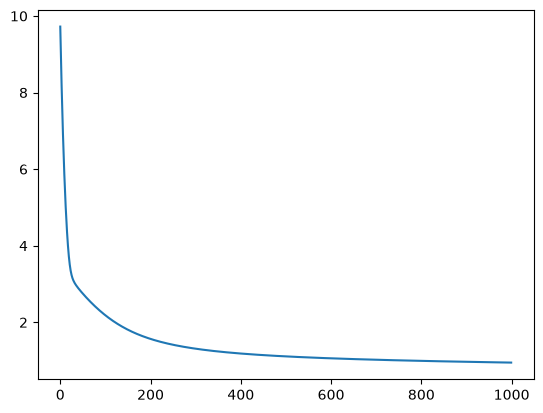

In [25]:
plt.plot(error_hist, label='Train');

In [26]:
w

array([[-1.9635825 ,  0.7711469 , -0.22916997],
       [ 0.63462517, -1.18634849, -0.31736116],
       [ 1.13017041,  0.61724947, -0.993813  ],
       [-2.00309652,  0.99989877,  0.36248098],
       [ 0.61910028, -0.34038875,  2.06120317]])

### Test

In [27]:
x_test_aug = np.hstack((np.ones((len(x_test), 1)), x_test))
x_test_aug.shape, y_test.shape

((30, 5), (30,))

In [28]:
y_hat_test = multi_logistic_regression(x_test_aug, w)
y_hat_test

array([[0.9240389 , 0.1226645 , 0.01288531],
       [0.01752338, 0.3163052 , 0.53864372],
       [0.04297416, 0.48343194, 0.54196902],
       [0.0881347 , 0.42717821, 0.35819393],
       [0.00942673, 0.44804616, 0.78842577],
       [0.10386959, 0.20736139, 0.27773809],
       [0.03221274, 0.41896436, 0.58414448],
       [0.87708471, 0.22412326, 0.01941136],
       [0.07221904, 0.28635888, 0.2773941 ],
       [0.10136192, 0.31396555, 0.30061831],
       [0.93688675, 0.1635956 , 0.01541898],
       [0.92750417, 0.10222033, 0.01882285],
       [0.89039756, 0.16822427, 0.02208576],
       [0.0164943 , 0.40476504, 0.4823164 ],
       [0.89840874, 0.2159093 , 0.0190368 ],
       [0.0518098 , 0.24755396, 0.29758287],
       [0.0091761 , 0.39923082, 0.54752601],
       [0.02665528, 0.30649706, 0.68700227],
       [0.17675279, 0.28388918, 0.28823852],
       [0.04896727, 0.38965525, 0.38043475],
       [0.1419103 , 0.22671851, 0.21548815],
       [0.06981029, 0.35304953, 0.3418482 ],
       [0.

In [29]:
accuracy(y_test, y_hat_test)

np.float64(0.8333333333333334)

In [30]:
y_test, np.argmax(y_hat_test, 1)

(array([0, 1, 1, 1, 2, 1, 2, 0, 1, 1, 0, 0, 0, 2, 0, 1, 2, 2, 1, 1, 1, 1,
        1, 0, 0, 2, 1, 2, 2, 0]),
 array([0, 2, 2, 1, 2, 2, 2, 0, 1, 1, 0, 0, 0, 2, 0, 2, 2, 2, 2, 1, 1, 1,
        1, 0, 0, 2, 1, 2, 2, 0]))